# code_113 · Sparse experts, routing loads and capacity fallback

**Book:** section 22.6. A self-contained architecture laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_22_GUIDE.md), [run evidence](../CHAPTER_22_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_113).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2313;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2313


<a id="routing-contract"></a>
 ## Stored experts and activated computations
 Generate sixty buildings × ten mixed operating records, split 40/10/10 by building. Three generator regimes have probabilities 0.7/0.2/0.1 and different response functions. Regime annotations audit routes; they do not train the router. A learned three-way router selects one of three 2→8→1 experts, and only assigned rows enter that expert. Its selected softmax weight scales the response. Compare a 2→10→1 dense model under the same declared thirty linear multiply-accumulate operations per record: router6 + selected expert24 versus dense20 +10. Bias additions, softmax, dispatch and nonlinear overhead are not equalized, so this is not a latency match. Both families get two declared development candidates and 400 updates per candidate.


,model,development_MSE,final_MSE,stored_parameters,linear_MACs_per_record,selected_rate,best_step,balance_weight,final_route_loads,route_generator_ARI
0,Dense,0.055651,0.044503,41,30,0.01,400,NaN,NaN,NaN
1,MoE balance 0,0.037287,0.037040,108,30,NaN,400,0.0,"[15, 65, 20]",0.321612
2,MoE balance 0.1,0.027001,0.048348,108,30,NaN,310,0.1,"[33, 38, 29]",0.233582


,capacity_factor,per_expert_capacity,fallback_count,final_MSE_including_mean_fallback,expert_rows_computed
0,1.00,34,4,0.063249,96
1,1.25,42,0,0.048348,100
2,2.00,67,0,0.048348,100


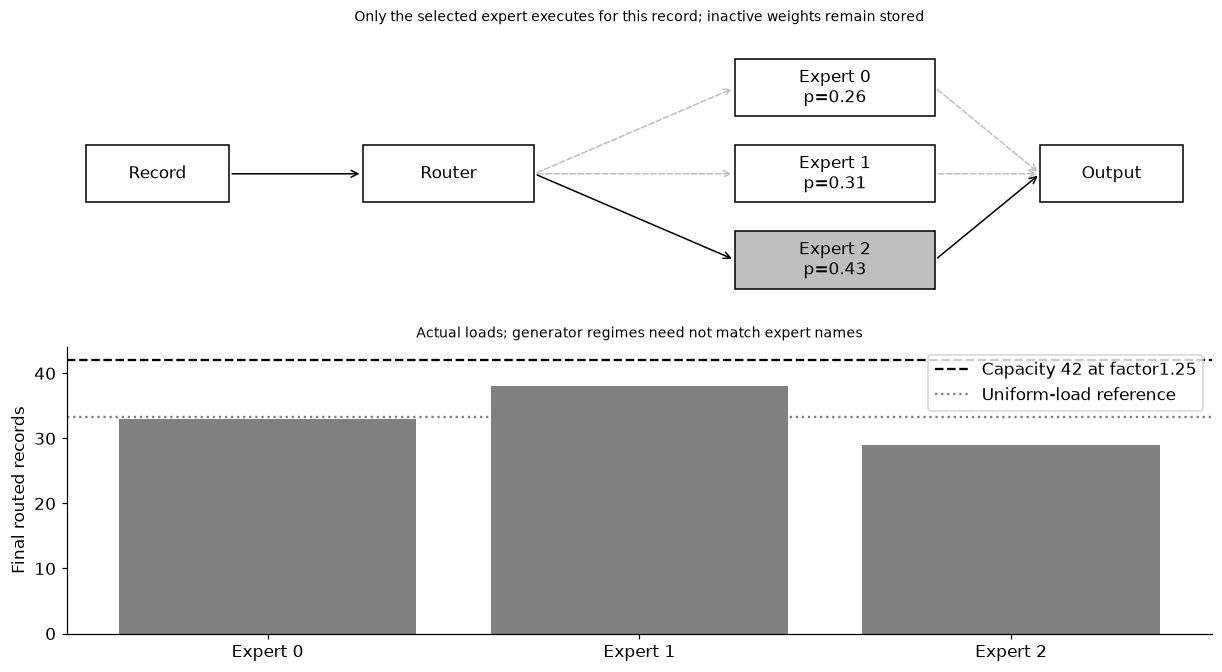

In [2]:
import copy
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
from matplotlib.patches import Rectangle
building=np.repeat(np.arange(60),10);regime=rng.choice(3,600,p=[.7,.2,.1]);raw=np.column_stack([np.array([-1.2,0.,1.2])[regime]+rng.normal(0,.2,600),rng.uniform(-1,1,600)]);x0,x1=raw.T
response=np.choose(regime,[np.sin(np.pi*x1),x1*x1-.5,-np.sin(np.pi*x1)])+.3*x0+.1*rng.normal(size=60)[building]+rng.normal(0,.05,600)
train=building<40;dev=(building>=40)&(building<50);final=building>=50;scaler=StandardScaler().fit(raw[train]);x=torch.tensor(scaler.transform(raw));center=float(response[train].mean());y=torch.tensor(response-center)
class SparseExperts(nn.Module):
    def __init__(self):super().__init__();self.router=nn.Linear(2,3);self.experts=nn.ModuleList([nn.Sequential(nn.Linear(2,8),nn.ReLU(),nn.Linear(8,1)) for _ in range(3)])
    def forward(self,values,capacity=None):
        probability=torch.softmax(self.router(values),dim=1);assignment=probability.argmax(1);prediction=values.new_zeros(len(values));fallback=torch.zeros(len(values),dtype=torch.bool);loads=[]
        for index,expert in enumerate(self.experts):
            assigned=torch.nonzero(assignment==index).ravel();loads.append(int(len(assigned)));accepted=assigned if capacity is None else assigned[:capacity]
            if capacity is not None:fallback[assigned[capacity:]]=True
            if len(accepted):prediction[accepted]=probability[accepted,index]*expert(values[accepted]).squeeze(-1)
        return prediction,probability,assignment,loads,fallback
    def dense_equivalent(self,values):
        probability=torch.softmax(self.router(values),dim=1);all_experts=torch.cat([expert(values) for expert in self.experts],1);assignment=probability.argmax(1);return (probability*all_experts).gather(1,assignment[:,None]).squeeze(1)
def make_dense():return nn.Sequential(nn.Linear(2,10),nn.ReLU(),nn.Linear(10,1))
dense_candidates=[];candidates=[];models={};rows=[]
for rate in [.005,.01]:
    torch.manual_seed(SEED);model=make_dense();optimizer=torch.optim.AdamW(model.parameters(),lr=rate,weight_decay=.001);best=float('inf')
    for step in range(400):
        optimizer.zero_grad();loss=torch.mean((model(x[train]).squeeze(1)-y[train])**2);loss.backward();optimizer.step()
        if (step+1)%10==0:
            with torch.no_grad():value=float(torch.mean((model(x[dev]).squeeze(1)-y[dev])**2))
            if value<best:best=value;state=copy.deepcopy(model.state_dict());best_step=step+1
    model.load_state_dict(state);model.eval();dense_candidates.append((best,rate,best_step,model));candidates.append({'family':'Dense','rate':rate,'balance_weight':0.,'development_MSE':best,'best_step':best_step})
best,rate,best_step,dense=min(dense_candidates,key=lambda r:r[0])
with torch.no_grad():dense_error=float(torch.mean((dense(x[final]).squeeze(1)-y[final])**2))
rows.append({'model':'Dense','development_MSE':best,'final_MSE':dense_error,'stored_parameters':sum(p.numel() for p in dense.parameters()),'linear_MACs_per_record':30,'selected_rate':rate,'best_step':best_step})
for balance in [0.,.1]:
    torch.manual_seed(SEED);model=SparseExperts();optimizer=torch.optim.AdamW(model.parameters(),lr=.01,weight_decay=.001);best=float('inf')
    for step in range(400):
        optimizer.zero_grad();prediction,probability,assignment,loads,_=model(x[train]);fraction=torch.tensor(loads,dtype=torch.float64)/train.sum();auxiliary=3*torch.sum(fraction.detach()*probability.mean(0));loss=torch.mean((prediction-y[train])**2)+balance*auxiliary;loss.backward();optimizer.step()
        if (step+1)%10==0:
            with torch.no_grad():prediction,_,_,_,_=model(x[dev]);value=float(torch.mean((prediction-y[dev])**2))
            if value<best:best=value;state=copy.deepcopy(model.state_dict());best_step=step+1
    model.load_state_dict(state);model.eval();models[balance]=model
    with torch.no_grad():prediction,probability,assignment,loads,_=model(x[final]);error=float(torch.mean((prediction-y[final])**2))
    rows.append({'model':f'MoE balance {balance:g}','balance_weight':balance,'development_MSE':best,'final_MSE':error,'stored_parameters':sum(p.numel() for p in model.parameters()),'linear_MACs_per_record':30,'best_step':best_step,'final_route_loads':loads,'route_generator_ARI':float(adjusted_rand_score(regime[final],assignment.numpy()))});candidates.append({'family':'MoE','rate':.01,'balance_weight':balance,'development_MSE':best,'best_step':best_step})
selected=min([r for r in rows if 'balance_weight' in r],key=lambda r:r['development_MSE'])['balance_weight'];model=models[selected]
assert rows[0]['stored_parameters']==41 and all(r['stored_parameters']==108 for r in rows[1:])
# Count actual rows reaching experts; this is sparse dispatch, not computing all experts then masking.
calls=[];handles=[expert.register_forward_pre_hook(lambda module,args:calls.append(len(args[0]))) for expert in model.experts]
with torch.no_grad():prediction,probability,assignment,loads,_=model(x[final]);torch.testing.assert_close(prediction,model.dense_equivalent(x[final]),atol=1e-12,rtol=1e-12)
for handle in handles:handle.remove()
# First sparse call consumes N rows, then the equivalence audit consumes 3N more.
sparse_rows=sum(calls[:sum(count>0 for count in loads)]);all_rows=sum(calls)-sparse_rows;assert sparse_rows==100 and all_rows==300
capacity_rows=[]
for factor in [1.,1.25,2.]:
    capacity=int(np.ceil(factor*100/3))
    with torch.no_grad():limited,_,_,_,fallback=model(x[final],capacity)
    capacity_rows.append({'capacity_factor':factor,'per_expert_capacity':capacity,'fallback_count':int(fallback.sum()),'final_MSE_including_mean_fallback':float(torch.mean((limited-y[final])**2)),'expert_rows_computed':int((~fallback).sum())})
capacity=int(np.ceil(1.25*100/3));permutation=torch.tensor(rng.permutation(100));inverse=torch.argsort(permutation)
with torch.no_grad():
    normal,_,_,_,flags=model(x[final],capacity);permuted,_,_,_,permuted_flags=model(x[final][permutation],capacity);order_changed_flags=int(torch.sum(flags!=permuted_flags[inverse]));permuted_error=float(torch.mean((permuted[inverse]-y[final])**2));uncapped_permuted,_,_,_,_=model(x[final][permutation]);torch.testing.assert_close(prediction,uncapped_permuted[inverse],atol=1e-12,rtol=1e-12)
RESULTS.update(comparisons=rows,candidates=candidates,selected_balance=selected,selected_final_loads=loads,capacity=capacity_rows,queue_order_changed_fallback_flags=order_changed_flags,queue_permuted_capacity_MSE=permuted_error,sparse_expert_rows=sparse_rows,dense_equivalent_expert_rows=all_rows,activated_parameters_per_record={'Dense':41,'MoE':42},linear_MACs_per_record={'Dense':30,'MoE':30},split_buildings=[40,10,10],fallback_raw_response=center,capacity_priority='input order within expert queue')
display(pd.DataFrame(rows));display(pd.DataFrame(capacity_rows))
fig,axes=plt.subplots(2,1,figsize=(11,6));ax=axes[0];ax.set(xlim=(0,12),ylim=(0,5));ax.axis('off');chosen=int(assignment[0]);p=probability[0].numpy()
boxes=[(.2,2,1.5,1,'Record'),(3.1,2,1.8,1,'Router')]+[(7,3.5-index*1.5,2.1,1,f'Expert {index}\np={p[index]:.2f}') for index in range(3)]+[(10.2,2,1.5,1,'Output')]
for index,(a,b,w,h,label) in enumerate(boxes):
    active=index==2+chosen;ax.add_patch(Rectangle((a,b),w,h,facecolor='.75' if active else 'white',edgecolor='black'));ax.text(a+w/2,b+h/2,label,ha='center',va='center')
ax.annotate('',xy=(3.1,2.5),xytext=(1.7,2.5),arrowprops={'arrowstyle':'->'})
for index in range(3):
    color='black' if index==chosen else '.75';style='-' if index==chosen else '--';ax.annotate('',xy=(7,4-index*1.5),xytext=(4.9,2.5),arrowprops={'arrowstyle':'->','color':color,'linestyle':style});ax.annotate('',xy=(10.2,2.5),xytext=(9.1,4-index*1.5),arrowprops={'arrowstyle':'->','color':color,'linestyle':style})
ax.set_title('Only the selected expert executes for this record; inactive weights remain stored')
axes[1].bar(range(3),loads,color='.5');axes[1].axhline(capacity,color='black',linestyle='--',label=f'Capacity {capacity} at factor1.25');axes[1].axhline(100/3,color='.5',linestyle=':',label='Uniform-load reference');axes[1].set(xticks=range(3),xticklabels=['Expert 0','Expert 1','Expert 2'],ylabel='Final routed records',title='Actual loads; generator regimes need not match expert names');axes[1].legend();plt.show()


<a id="capacity-contract"></a>
 ## Capacity is a separate serving policy
 The selected balance penalty comes only from development response error. Uniform routing load is not automatically the right operating-regime partition, especially for this imbalanced generator. Uncapped predictions are order-invariant. Capacity accepts the first arriving records within each expert queue; overflow records receive the declared training-mean fallback and an explicit flag. All final queries remain in the error denominator. Permuting queue order can change which records fall back. Stored parameters, activated parameters, linear matrix products, dispatch overhead and measured wall time are different quantities. No unmeasured speedup, calibrated gating probability or physical-regime identification is claimed.


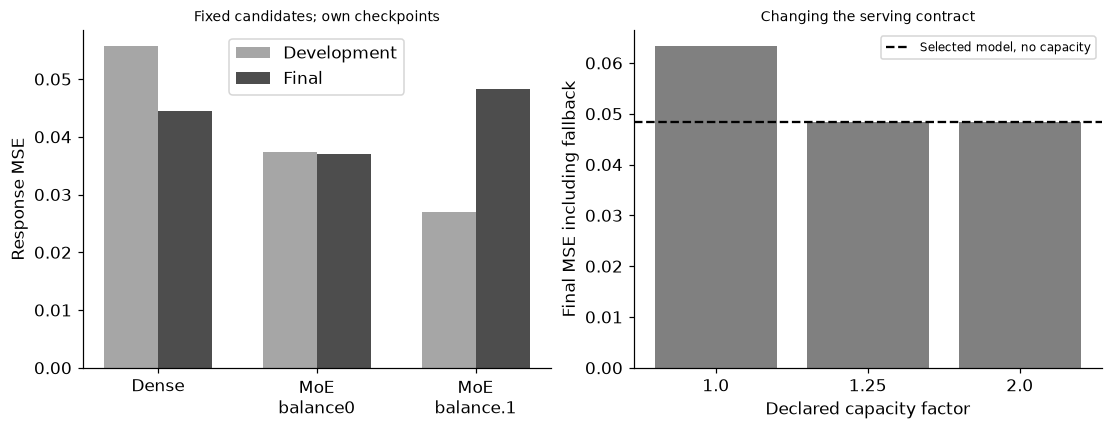

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,3.8));xx=np.arange(3)
axes[0].bar(xx-.17,[r['development_MSE'] for r in rows],.34,color='.65',label='Development');axes[0].bar(xx+.17,[r['final_MSE'] for r in rows],.34,color='.3',label='Final');axes[0].set(xticks=xx,xticklabels=['Dense','MoE\nbalance0','MoE\nbalance.1'],ylabel='Response MSE',title='Fixed candidates; own checkpoints');axes[0].legend()
axes[1].bar(range(3),[r['final_MSE_including_mean_fallback'] for r in capacity_rows],color='.5');axes[1].axhline(next(r['final_MSE'] for r in rows if r.get('balance_weight')==selected),color='black',linestyle='--',label='Selected model, no capacity');axes[1].set(xticks=range(3),xticklabels=['1.0','1.25','2.0'],xlabel='Declared capacity factor',ylabel='Final MSE including fallback',title='Changing the serving contract');axes[1].legend(fontsize=8);plt.show()
assert sum(loads)==100 and all(r['fallback_count']+r['expert_rows_computed']==100 for r in capacity_rows)


In [4]:
summary={'example_id':'code_113','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual selected-row expert execution', 'learned top-one routing', 'load-balance ablation', 'declared linear-MAC budget', 'capacity fallback and queue order'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual selected-row expert execution", "learned top-one routing", "load-balance ablation", "declared linear-MAC budget", "capacity fallback and queue order"], "elapsed_seconds": 1.27, "example_id": "code_113", "hardware": "Darwin arm64 CPU", "results": {"activated_parameters_per_record": {"Dense": 41, "MoE": 42}, "candidates": [{"balance_weight": 0.0, "best_step": 400, "development_MSE": 0.07005317348500308, "family": "Dense", "rate": 0.005}, {"balance_weight": 0.0, "best_step": 400, "development_MSE": 0.05565071234539649, "family": "Dense", "rate": 0.01}, {"balance_weight": 0.0, "best_step": 400, "development_MSE": 0.037286898960384576, "family": "MoE", "rate": 0.01}, {"balance_weight": 0.1, "best_step": 310, "development_MSE": 0.027001110773952244, "family": "MoE", "rate": 0.01}], "capacity": [{"capacity_factor": 1.0, "expert_rows_computed": 96, "fallback_count": 4, "final_MSE_including_mean_fallback": 0.06324894568883678, "per_exper